# 01 · Data (plan Steps 01–02)

This notebook builds the clean spot spreads, the filter inputs and the event calendar. All the logic lives in `src/oilrv/`; this notebook runs it and shows the results.

**Sources**
- **FRED:** `DCOILWTICO`, `DCOILBRENTEU`, `DGASNYH`, `OVXCLS`.
- **EIA:** the daily NY Harbor ULSD spot price, and the weekly stocks history (crude ex-SPR, Cushing, gasoline, distillate, refinery utilisation).
- **Others:** the Caldara–Iacoviello daily GPR index, CFTC disaggregated COT (managed money in CL, RB and HO), NHC HURDAT2, and the hand-built `data/calendars/events_manual.csv`.

**Spot proxy.** Every result built on these spot series is a *spot proxy*. The binding verdict uses Bloomberg futures (PREREGISTRATION.md §5), which `oilrv.futures` loads once they are exported.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image
from oilrv.config import load_config, ROOT
from oilrv.data import load_clean, load_features
from oilrv.calendars import load_events
import sys; sys.path.insert(0, str(ROOT / 'scripts'))
import build_data

summary = build_data.main(refresh=False)   # uses cached raw files if < 1 day old
pd.Series({k: v for k, v in summary.items() if not isinstance(v, dict)}, name='value').to_frame()

,value
source,spot
first_date,2007-01-03
last_date,2026-10-20
n_days,4848
max_gap_calendar_days,10
n_days_flag_apr2020,5
wti_min,-36.98
crack321_median,19.42
crack321_range,"[-1.62, 81.86]"
brent_wti_median,3.76


## Pre-registered gates and base rules
These were fixed in `config.yaml` on 2026-10-24, before any data was downloaded, and tagged in git as `prereg-2026-10-24`. `tests/test_preregistration.py` fails if any of them are edited.

In [2]:
cfg = load_config()
pd.DataFrame({'value': {**{f'gate.{k}': v for k, v in cfg['gates'].items()},
                        **{f'strategy.{k}': v for k, v in cfg['strategy'].items()}}})

,value
gate.min_net_sharpe,0.5
gate.min_round_trips,20
gate.min_positive_subperiods,2
gate.entry_grid_stability,{'min_sharpe_all_grid_points': 0.0}
gate.stress_filter,"{'windows': ['ukraine', 'hormuz'], 'filtered_g..."
strategy.entry_z,2.0
strategy.exit_z,0.5
strategy.stop_z,4.0
strategy.time_stop_halflives,3.0
strategy.rearm_z,2.0


## Clean spot spreads ($/bbl)

In [3]:
px, sp = load_clean()
sp[['crack321', 'brent_wti', 'ho_rb', 'cl_bbl', 'brent_bbl', 'rb_bbl', 'ho_bbl']].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
crack321,4848.0,21.66,11.97,-1.62,13.78,19.42,25.79,81.86
brent_wti,4848.0,4.96,6.12,-22.18,1.36,3.76,6.89,54.34
ho_rb,4848.0,8.20,12.46,-18.23,0.80,5.17,12.52,99.46
cl_bbl,4848.0,73.03,21.69,-36.98,56.50,72.13,89.56,145.31
brent_bbl,4848.0,77.99,24.18,9.12,61.09,75.13,97.44,143.95
rb_bbl,4848.0,91.96,26.34,18.23,72.62,89.17,113.34,189.38
ho_bbl,4848.0,100.16,33.06,25.28,78.12,94.16,123.66,225.33


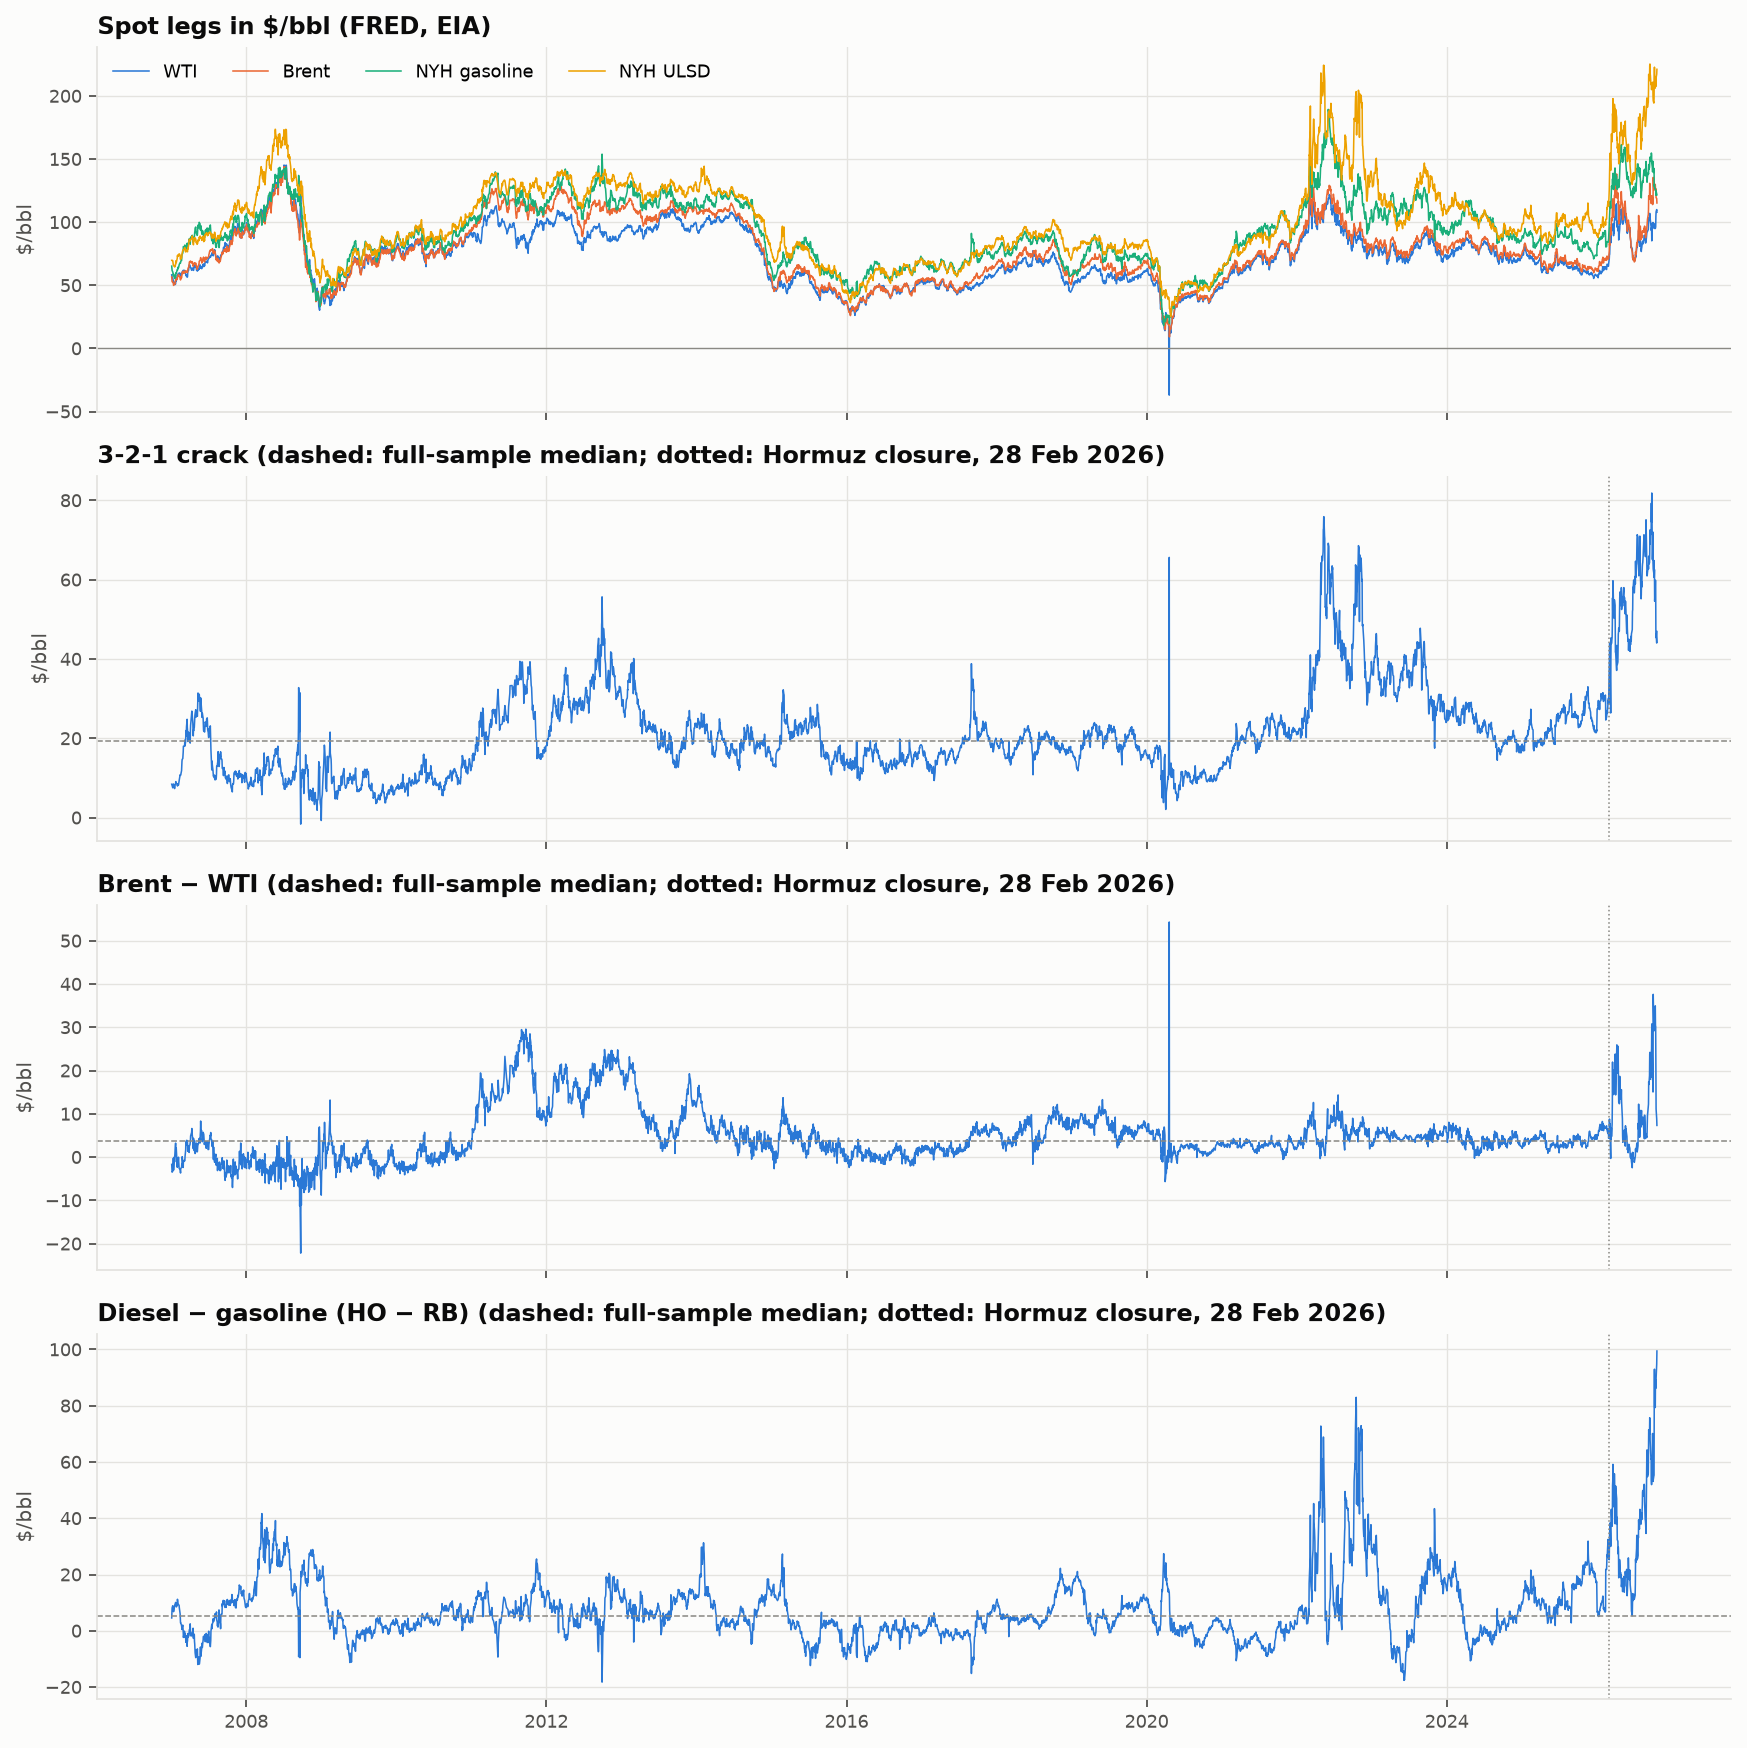

In [4]:
Image(str(ROOT / 'output/figures/01_prices_and_spreads.png'))

### Check against the plan's market facts
- **20 Oct 2026, EIA spot:** the 3-2-1 crack should be about \$47/bbl, the diesel crack about \$113 and Brent–WTI about \$7.
- **Long-run 3-2-1 median:** about \$19.

In [5]:
last = sp.loc['2026-10-20']
pd.Series({'crack321': last['crack321'], 'diesel crack (HO - CL)': last['ho_bbl'] - last['cl_bbl'],
           'gasoline crack (RB - CL)': last['rb_bbl'] - last['cl_bbl'], 'brent_wti': last['brent_wti'],
           'crack321 median since 2007': sp['crack321'].median()}).round(2).to_frame('$/bbl')

,$/bbl
crack321,46.94
diesel crack (HO - CL),113.24
gasoline crack (RB - CL),13.78
brent_wti,7.33
crack321 median since 2007,19.42


In [6]:
# Annual means: how far 2022 and 2026 sit outside history
sp[['crack321', 'brent_wti', 'ho_rb']].groupby(sp.index.year).mean().round(1).T

date,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
crack321,15.7,10.6,8.5,10.0,25.3,31.8,22.9,19.1,19.8,14.6,18.2,18.3,19.2,11.3,20.4,43.2,34.8,22.7,23.5,50.9
brent_wti,0.2,-2.7,-0.2,0.1,16.5,17.6,10.6,5.8,3.7,0.4,3.4,6.1,7.3,2.5,2.7,6.0,4.9,3.9,3.6,9.8
ho_rb,3.7,22.0,1.4,4.2,10.2,7.4,8.4,7.9,1.6,-1.6,0.7,7.1,8.0,2.9,-2.4,26.9,9.9,4.0,13.5,33.4


### Review flags
- **Spike flags** mark a move larger than 5 × the trailing sd that mostly reverses the next day. Nothing is dropped.
  - Most crack and HO−RB flags fall on 1 Feb or 1 Mar. Those are **NY Harbor spot gasoline grade (RVP) switches**: a real feature of the spot series, and one more reason the binding test uses futures.
- **`flag_apr2020`** marks the week WTI spot settled at −\$36.98. It is kept in the core run and dropped in a pre-registered robustness run.

In [7]:
flags = {c: [d.date().isoformat() for d in sp.index[sp[f'spike_{c}']]] for c in ['crack321', 'brent_wti', 'ho_rb']}
pd.Series(flags).to_frame('flagged dates')

,flagged dates
crack321,"[2008-03-28, 2010-02-01, 2018-03-01, 2019-03-0..."
brent_wti,"[2020-04-20, 2023-10-02, 2026-03-09]"
ho_rb,"[2008-09-18, 2010-02-01, 2013-03-01, 2013-08-2..."


In [8]:
sp.loc['2020-04-16':'2020-04-27', ['cl_bbl', 'crack321', 'brent_wti', 'flag_apr2020']]

,cl_bbl,crack321,brent_wti,flag_apr2020
date,,,,
2020-04-16,19.82,10.322,-1.13,False
2020-04-17,18.31,12.672,1.44,False
2020-04-20,-36.98,65.624,54.34,True
2020-04-21,8.91,14.820,0.21,True
2020-04-22,13.64,13.324,0.13,True
2020-04-23,15.06,11.862,0.00,True
2020-04-24,15.99,10.764,-0.12,True
2020-04-27,12.17,13.002,3.00,False


## Filter inputs, each stamped on the day it became known
- **Weekly EIA stocks** count as known from the Thursday after the week ends. `inventory_dev_5y` is total crude ex-SPR + gasoline + distillate, against the same week in the previous five years.
- **COT positions** count as known from the Friday release.
- **GPR** is lagged one day.
- Percentile and z-score versions are built in the regime step (Part 5), because they need rolling windows.

In [9]:
feats = load_features()
fig, ax = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
for a, (col, lab) in zip(ax, [('ovx', 'OVX'), ('gpr', 'Daily GPR (lagged 1 day)'),
                              ('inventory_dev_5y', 'US stocks vs 5-year same-week average (%)'),
                              ('mm_net_cl', 'Managed-money net, NYMEX WTI (contracts)')]):
    a.plot(feats.index, feats[col], lw=0.7); a.set_title(lab)
fig.tight_layout()

In [10]:
feats.loc['2010':].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
ovx,4110.0,38.0,17.4,14.5,29.2,34.7,43.1,325.2
gpr,4110.0,111.0,57.2,0.0,73.4,100.4,136.3,540.8
crude_ex_spr,4110.0,417003.0,58876.8,301123.0,355163.0,426544.0,455922.0,540722.0
cushing,4110.0,39482.2,13758.5,17899.0,27727.0,36783.5,49260.0,69420.0
gasoline,4110.0,227237.5,13838.2,195408.0,217354.0,226147.0,236189.0,263234.0
distillate,4110.0,132635.9,18496.9,100799.0,118055.2,127952.0,147767.0,179977.0
refinery_util,4110.0,88.9,5.2,56.0,86.4,89.6,92.6,98.1
total_stocks,4110.0,776876.4,72685.6,651141.0,711522.0,778387.0,814902.0,972555.0
inventory_dev_5y,4110.0,3.2,9.4,-15.0,-3.5,0.7,8.1,27.7
crude_ex_spr_dev_5y,4110.0,6.5,12.8,-15.6,-2.4,3.0,10.2,41.9


## Event calendar
- `verified`:
  - **yes:** checked this session against the linked source.
  - **partial:** confirmed only by a search summary or a secondary report.
  - **inferred:** from the first-Sunday monthly pattern of the 2025–26 core-country meetings.
  - **no:** compiled from memory. These still need checking against the opec.org press-release archive, which blocks automated access.
- Only **scheduled** OPEC meetings and hurricane landfalls drive the entry blackout.
- STEO and IEA report dates are left out, because the EIA and IEA archives refused automated access. They only feed the ungated `event_within_3d` robustness feature.

In [11]:
ev = load_events()
pd.crosstab(ev['type'], ev['verified'])

verified,inferred,no,partial,yes
type,,,,
HORMUZ,0,0,0,10
HURRICANE,0,0,0,19
OPEC,4,75,2,17
SPR,0,4,0,2


In [12]:
ev[ev['type'].isin(['HURRICANE', 'HORMUZ', 'SPR'])][['date', 'type', 'name', 'verified']]

,date,type,name,verified
2,2007-09-13,HURRICANE,"Humberto (landfall 29.6N 94.3W, 80 kt)",yes
6,2008-07-23,HURRICANE,"Dolly (landfall 26.4N 97.2W, 75 kt)",yes
7,2008-09-01,HURRICANE,"Gustav (landfall 29.2N 90.7W, 90 kt)",yes
9,2008-09-13,HURRICANE,"Ike (landfall 29.3N 94.7W, 95 kt)",yes
20,2011-06-23,SPR,IEA collective action (Libya),no
23,2012-08-29,HURRICANE,"Isaac (landfall 28.9N 89.4W, 70 kt)",yes
36,2017-08-26,HURRICANE,"Harvey (landfall 28.0N 96.9W, 115 kt)",yes
37,2017-10-08,HURRICANE,"Nate (landfall 29.1N 89.2W, 75 kt)",yes
41,2018-10-10,HURRICANE,"Michael (landfall 30.0N 85.5W, 140 kt)",yes
46,2019-07-13,HURRICANE,"Barry (landfall 29.6N 92.2W, 65 kt)",yes


In [13]:
cal = pd.read_csv(ROOT / 'data/clean/event_features.csv', index_col=0, parse_dates=True)
cal.tail(15)

,days_to_opec,days_to_hurricane,event_blackout,event_within_3d,hurricane_season,days_since_hormuz_closure
date,,,,,,
2026-09-30,3.0,8.0,False,True,True,3.0
2026-10-01,2.0,7.0,True,True,True,4.0
2026-10-02,1.0,6.0,True,True,True,5.0
2026-10-05,20.0,5.0,False,False,True,8.0
2026-10-06,19.0,4.0,False,False,True,9.0
2026-10-07,18.0,3.0,False,True,True,10.0
2026-10-08,17.0,2.0,True,True,True,11.0
2026-10-09,16.0,1.0,True,True,True,12.0
2026-10-12,15.0,NaN,False,False,True,15.0


## Futures (Bloomberg)
`oilrv.futures` builds same-delivery-month legs, rolled 5 business days before expiry, with additive back-adjustment. It needs `data/raw/bloomberg/{CL,CO,XB,HO}.csv`; see the README in that folder. It is tested on synthetic curves in `tests/test_data.py`.

In [14]:
from oilrv import futures
print('Bloomberg export present:', futures.available())

Bloomberg export present: False
